# บทที่ 4 · วาดกราฟเส้นด้วย pyplot

**matplotlib** คือไลบรารีวาดกราฟยอดนิยมของ Python และ `pyplot` คือโมดูลที่เราเรียกใช้บ่อยที่สุด (นิยม import เป็น `plt`) ทำงานคล้ายปากกา: สั่งทีละคำสั่ง เพิ่มทีละชั้น จนได้กราฟตามต้องการ

## สูตรวาดกราฟ 4 ขั้น
1. **เตรียมข้อมูล** — มักเป็นคอลัมน์ของ DataFrame
2. **เลือกชนิดกราฟ** — `plt.plot(x, y)` สำหรับกราฟเส้น
3. **ตกแต่ง** — ชื่อกราฟ ชื่อแกน สี กริด
4. **สั่งแสดง** — `plt.show()` (ใน VS Code จะแสดงกราฟใต้เซลล์)

> ⚠️ **เรื่องฟอนต์:** กราฟในหน่วยนี้ใช้ข้อความภาษาอังกฤษบนแกนและชื่อกราฟ เพราะฟอนต์มาตรฐานของ matplotlib ยังไม่มีตัวอักษรไทย — หากนำไปใช้จริงและต้องการกราฟภาษาไทย ต้องติดตั้งฟอนต์ไทย (เช่น TH Sarabun New) ให้ matplotlib ก่อน

กราฟเส้นเหมาะกับข้อมูลที่ไล่ตาม **ลำดับ** (โดยเฉพาะเวลา) — เราจะใช้ค่าอุณหภูมิรายเดือนจริงจากการ์ดข้อมูลบทที่ 1

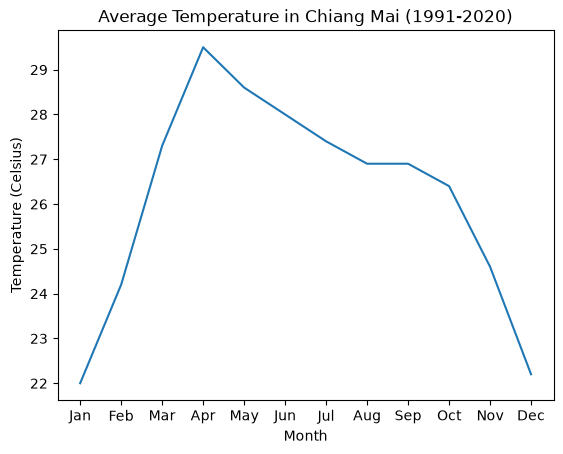

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/thai_monthly_climate_1991_2020.csv")

# กราฟเส้นแรก: อุณหภูมิเฉลี่ยรายเดือนของเชียงใหม่
plt.plot(df["month_en"], df["cm_mean_c"])
plt.title("Average Temperature in Chiang Mai (1991-2020)")
plt.xlabel("Month")
plt.ylabel("Temperature (Celsius)")
plt.show()

## ตกแต่งให้อ่านง่าย

คนเรียนจำนวนมากวาดกราฟแล้วจบแค่เส้นเปล่า — กราฟที่ดีต้องมีจุดข้อมูล เส้นกริด และขนาดที่เหมาะ:

| พารามิเตอร์ | ตัวเลือกที่ใช้บ่อย |
|---|---|
| `color` | `"red"`, `"green"`, หรือรหัสสี `"#B33A2B"` |
| `marker` | `"o"` จุดกลม · `"s"` สี่เหลี่ยม · `"^"` สามเหลี่ยม |
| `linestyle` | `"-"` ทึบ · `"--"` ประ · `"-."` ประ-ขีด |
| `figsize` | (กว้าง, สูง) หน่วยนิ้ว เช่น `(9, 4)` |

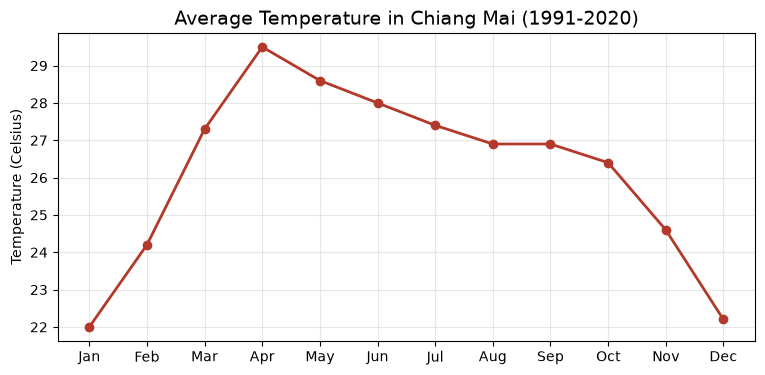

In [2]:
# ตกแต่ง: สี + จุดข้อมูล + กริด + ขนาด
plt.figure(figsize=(9, 4))
plt.plot(df["month_en"], df["cm_mean_c"],
         color="#B33A2B", marker="o", linestyle="-", linewidth=2)
plt.grid(True, alpha=0.3)
plt.title("Average Temperature in Chiang Mai (1991-2020)", fontsize=14)
plt.ylabel("Temperature (Celsius)")
plt.show()

## หลายเส้นในกราฟเดียว + `legend`

เรียก `plt.plot()` หลายครั้งก่อน `plt.show()` ก็จะได้หลายเส้นซ้อนกัน กำกับ `label` แต่ละเส้นแล้วสั่ง `plt.legend()`

คราวนี้เทียบ 3 เมืองพร้อมกัน: เชียงใหม่ (เหนือ) กทม. (กลาง) ภูเก็ต (ใต้ ทะเลอันดามัน)

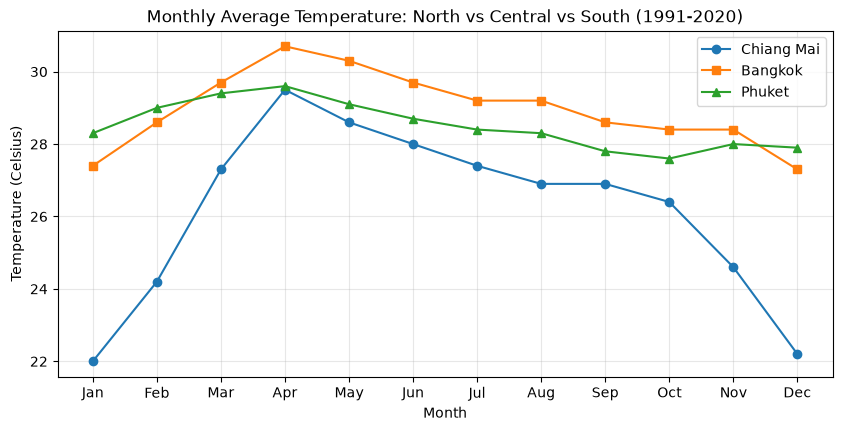

In [3]:
# เทียบอุณหภูมิ 3 เมืองในกราฟเดียว
plt.figure(figsize=(10, 4.5))
plt.plot(df["month_en"], df["cm_mean_c"],  marker="o", label="Chiang Mai")
plt.plot(df["month_en"], df["bkk_mean_c"], marker="s", label="Bangkok")
plt.plot(df["month_en"], df["phkt_mean_c"], marker="^", label="Phuket")
plt.title("Monthly Average Temperature: North vs Central vs South (1991-2020)")
plt.ylabel("Temperature (Celsius)")
plt.xlabel("Month")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# สังเกต: ภูเก็ตเส้นแบนราบเกือบตลอดปี (ทะเลคลื่นลม) ส่วนเชียงใหมว "ขึ้นลง" ตามฤดูชัดเจน!

## 🎯 ภารกิจบทที่ 4 (ส่งคำตอบใน Moodle)

อุณหภูมิของเชียงใหม่ "ขึ้นลง" ตามฤดู แต่กทม./ภูเก็ตแทบไม่ขยับ — **ความต่างระหว่างเดือนที่ร้อนที่สุดกับเดือนที่เย็นที่สุดของเชียงใหม่** กี่องศาเซลเซียส? (ทศนิยม 1 ตำแหน่ง)

In [4]:
# ภารกิจ 4: ช่วงอุณหภูมิ (range) ของเชียงใหม่
temp_range = df["cm_mean_c"].max() - df["cm_mean_c"].min()
print("เดือนร้อนสุด", df["cm_mean_c"].max(), "°C | เดือนเย็นสุด", df["cm_mean_c"].min(), "°C")
print("คำตอบภารกิจบทที่ 4 =", round(temp_range, 1))

เดือนร้อนสุด 29.5 °C | เดือนเย็นสุด 22.0 °C
คำตอบภารกิจบทที่ 4 = 7.5
